In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os
from google.colab import drive
import pandas as pd

# 1. إعادة التأكيد على ربط الدرايف
drive.mount('/content/drive')

# 2. البحث عن مكان ملف scores.csv تلقائياً داخل الدرايف
found_path = None
for root, dirs, files in os.walk('/content/drive/MyDrive'):
    if 'scores.csv' in files:
        found_path = os.path.join(root, 'scores.csv')
        break

if found_path:
    print(f"تم العثور على الملف في المسار: {found_path}")
    scores_df = pd.read_csv(found_path)
    display(scores_df.head())
else:
    print("لم يتم العثور على ملف scores.csv داخل Google Drive.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
تم العثور على الملف في المسار: /content/drive/MyDrive/Depression_Dataset/data/scores.csv


,number,days,gender,age,afftype,melanch,inpatient,edu,marriage,work,madrs1,madrs2
0,condition_1,11,2,35-39,2.0,2.0,2.0,6-10,1.0,2.0,19.0,19.0
1,condition_2,18,2,40-44,1.0,2.0,2.0,6-10,2.0,2.0,24.0,11.0
2,condition_3,13,1,45-49,2.0,2.0,2.0,6-10,2.0,2.0,24.0,25.0
3,condition_4,13,2,25-29,2.0,2.0,2.0,11-15,1.0,1.0,20.0,16.0
4,condition_5,13,2,50-54,2.0,2.0,2.0,11-15,2.0,2.0,26.0,26.0


In [ ]:
import os
import pandas as pd

# استخراج مسار المجلد الرئيسي للبيانات ديناميكياً من موقع scores.csv
base_dir = os.path.dirname(found_path)

# تحديد مسار ملف condition_1.csv
sample_condition_path = os.path.join(base_dir, 'condition', 'condition_1.csv')

# قراءة الملف وعرض البيانات والمعلومات
condition_sample_df = pd.read_csv(sample_condition_path)

print("--- أول 5 أسطر من condition_1.csv ---")
display(condition_sample_df.head())

print("\n--- معلومات عن الأعمدة وأنواع البيانات ---")
print(condition_sample_df.info())

--- أول 5 أسطر من condition_1.csv ---


,timestamp,date,activity
0,2003-05-07 12:00:00,2003-05-07,0
1,2003-05-07 12:01:00,2003-05-07,143
2,2003-05-07 12:02:00,2003-05-07,0
3,2003-05-07 12:03:00,2003-05-07,20
4,2003-05-07 12:04:00,2003-05-07,166



--- معلومات عن الأعمدة وأنواع البيانات ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23244 entries, 0 to 23243
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   timestamp  23244 non-null  object
 1   date       23244 non-null  object
 2   activity   23244 non-null  int64 
dtypes: int64(1), object(2)
memory usage: 544.9+ KB
None


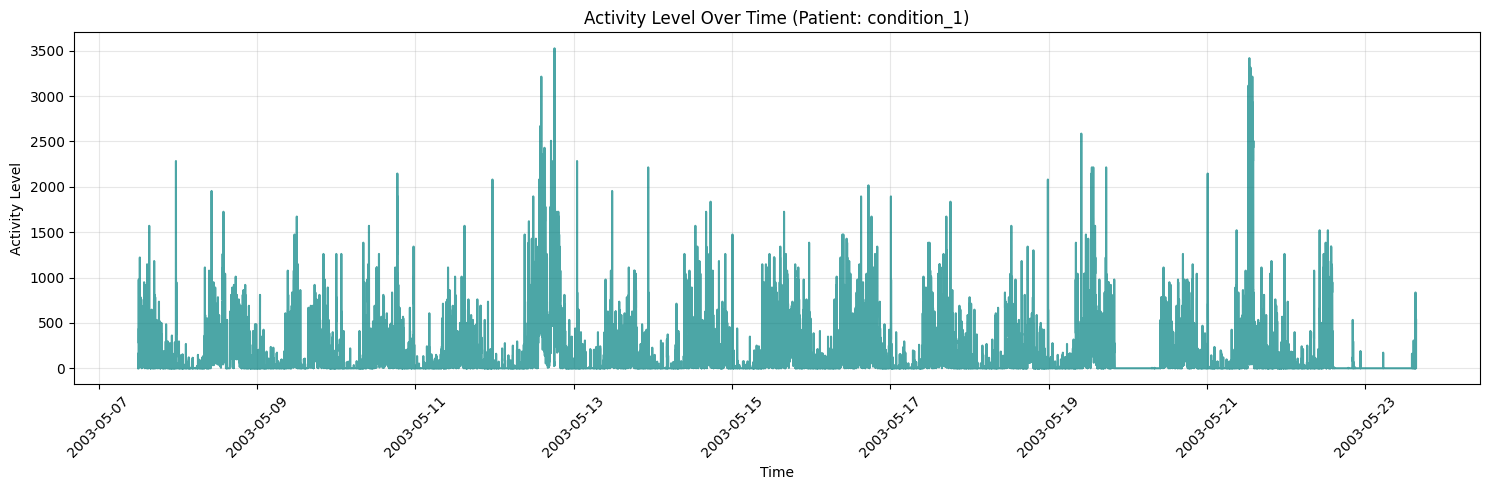


--- إحصائيات سريعة عن المريض condition_1 ---
إجمالي عدد الدقائق المسجلة: 23244 دقيقة
متوسط مستوى النشاط: 146.95
أعلى مستوى نشاط تم تسجيله: 3526
نسبة الدقائق التي لا يوجد بها حركة (وقت النوم أو الراحة التامة): 46.90%


In [ ]:
import matplotlib.pyplot as plt

# 1. تحويل عمود timestamp إلى نوع بيانات datetime لسهولة التعامل مع التواريخ
condition_sample_df['timestamp'] = pd.to_datetime(condition_sample_df['timestamp'])

# 2. رسم النشاط الحركي للمريض على مدار الوقت
plt.figure(figsize=(15, 5))
plt.plot(condition_sample_df['timestamp'], condition_sample_df['activity'], color='teal', alpha=0.7)
plt.title('Activity Level Over Time (Patient: condition_1)')
plt.xlabel('Time')
plt.ylabel('Activity Level')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 3. إحصائيات سريعة عن نشاط المريض
print("\n--- إحصائيات سريعة عن المريض condition_1 ---")
print(f"إجمالي عدد الدقائق المسجلة: {len(condition_sample_df)} دقيقة")
print(f"متوسط مستوى النشاط: {condition_sample_df['activity'].mean():.2f}")
print(f"أعلى مستوى نشاط تم تسجيله: {condition_sample_df['activity'].max()}")
print(f"نسبة الدقائق التي لا يوجد بها حركة (وقت النوم أو الراحة التامة): {(condition_sample_df['activity'] == 0).mean() * 100:.2f}%")

In [ ]:
import os
import pandas as pd

base_dir = os.path.dirname(found_path)

# دالة لاستخراج الخصائص الإحصائية من ملف الحركة الخاص بكل مريض
def extract_features(file_path):
    df = pd.read_csv(file_path)
    return {
        'mean_activity': df['activity'].mean(),
        'std_activity': df['activity'].std(),
        'max_activity': df['activity'].max(),
        'zero_activity_ratio': (df['activity'] == 0).mean()
    }

extracted_data = []

# المرور على مجلدات condition و control
for group in ['condition', 'control']:
    group_dir = os.path.join(base_dir, group)
    if os.path.exists(group_dir):
        for filename in sorted(os.listdir(group_dir)):
            if filename.endswith('.csv'):
                subject_id = filename.replace('.csv', '')
                file_path = os.path.join(group_dir, filename)

                # استخراج الميزات
                feats = extract_features(file_path)
                feats['number'] = subject_id
                feats['target'] = 1 if group == 'condition' else 0  # 1 = مكتئب (condition)، 0 = غير مكتئب (control)

                extracted_data.append(feats)

# تحويل الميزات المجمعة إلى DataFrame
time_series_features_df = pd.DataFrame(extracted_data)

# دمج الخصائص الإحصائية مع ملف scores_df الرئيسي بناءً على رقم المريض (number)
final_df = pd.merge(scores_df, time_series_features_df, on='number', how='inner')

print(f"--- تم استخراج البيانات وتجميعها بنجاح! ---")
print(f"حجم الجدول النهائي (الأسطر، الأعمدة): {final_df.shape}")
display(final_df.head())

--- تم استخراج البيانات وتجميعها بنجاح! ---
حجم الجدول النهائي (الأسطر، الأعمدة): (55, 17)


,number,days,gender,age,afftype,melanch,inpatient,edu,marriage,work,madrs1,madrs2,mean_activity,std_activity,max_activity,zero_activity_ratio,target
0,condition_1,11,2,35-39,2.0,2.0,2.0,6-10,1.0,2.0,19.0,19.0,146.948030,294.592424,3526,0.469024,1
1,condition_2,18,2,40-44,1.0,2.0,2.0,6-10,2.0,2.0,24.0,11.0,153.664748,330.801716,4228,0.000051,1
2,condition_3,13,1,45-49,2.0,2.0,2.0,6-10,2.0,2.0,24.0,25.0,265.299704,399.881083,3847,0.000000,1
3,condition_4,13,2,25-29,2.0,2.0,2.0,11-15,1.0,1.0,20.0,16.0,274.866998,446.048930,6776,0.391446,1
4,condition_5,13,2,50-54,2.0,2.0,2.0,11-15,2.0,2.0,26.0,26.0,167.245987,298.719629,4609,0.374959,1


In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

# 1. دالة تحويل النطاقات النصية (مثل 35-39) إلى رقم القيمة المتوسطة (Midpoint)
def range_to_midpoint(val):
    if pd.isna(val):
        return np.nan
    val_str = str(val).strip()
    if '-' in val_str:
        parts = val_str.split('-')
        try:
            return (float(parts[0]) + float(parts[1])) / 2
        except:
            return np.nan
    try:
        return float(val_str)
    except:
        return np.nan

# 2. تنظيف الأعمدة وتحويلها إلى أرقام
df_clean = final_df.copy()
df_clean['age'] = df_clean['age'].apply(range_to_midpoint)
df_clean['edu'] = df_clean['edu'].apply(range_to_midpoint)

# تعبئة أي قيم مفقودة بمتوسط العمود (Median)
df_clean = df_clean.fillna(df_clean.median(numeric_only=True))

# 3. فصل الخصائص (X) والهدف المطلوب توقعه (y)
X = df_clean.drop(columns=['number', 'target'])
y = df_clean['target']

# 4. تقسيم البيانات إلى مجموعة تدريب (Train) ومجموعة اختبار (Test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 5. تدريب نموذج Random Forest Classifier
model = RandomForestClassifier(random_state=42, n_estimators=100)
model.fit(X_train, y_train)

# 6. تقييم الموديل
y_pred = model.predict(X_test)
acc = accuracy_score(y_test, y_pred)

print(f"--- دقة النموذج (Accuracy): {acc * 100:.2f}% --- \n")
print("تقرير الأداء التفصيلي (Classification Report):")
print(classification_report(y_test, y_pred, target_names=['Control (0)', 'Depressed (1)']))

--- دقة النموذج (Accuracy): 81.82% --- 

تقرير الأداء التفصيلي (Classification Report):
               precision    recall  f1-score   support

  Control (0)       0.75      1.00      0.86         6
Depressed (1)       1.00      0.60      0.75         5

     accuracy                           0.82        11
    macro avg       0.88      0.80      0.80        11
 weighted avg       0.86      0.82      0.81        11



In [ ]:
# تثبيت مكتبة XGBoost لو لم تكن مثبتة
!pip install xgboost -q

import joblib
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# 1. تعريف الموديلات المختلفة للمقارنة
models = {
    'Random Forest': RandomForestClassifier(random_state=42),
    'XGBoost': XGBClassifier(random_state=42, eval_metric='logloss'),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'SVM': SVC(probability=True, random_state=42)
}

results = []
best_acc = 0
best_model_name = ""
best_model_obj = None

# 2. تدريب وتقييم كل موديل
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)

    results.append({
        'Model': name,
        'Accuracy': f"{acc*100:.2f}%",
        'Precision': f"{prec*100:.2f}%",
        'Recall': f"{rec*100:.2f}%",
        'F1-Score': f"{f1*100:.2f}%"
    })

    if acc > best_acc:
        best_acc = acc
        best_model_name = name
        best_model_obj = model

# 3. عرض جدول المقارنة بين الموديلات
results_df = pd.DataFrame(results)
print("--- جدول مقارنة أدوات وموديلات الذكاء الاصطناعي ---")
display(results_df)

# 4. حفظ أفضل موديل لعمل Integration مع الـ Backend
model_filename = 'best_depression_model.pkl'
joblib.dump(best_model_obj, model_filename)

print(f"\n تم اختيار أفضل موديل وهو ({best_model_name}) بدقة {best_acc*100:.2f}%")
print(f" تم حفظ الموديل بنجاح باسم '{model_filename}' ليكون جاهزاً للربط مع الـ Backend (Box 01)!")

--- جدول مقارنة أدوات وموديلات الذكاء الاصطناعي ---


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,Model,Accuracy,Precision,Recall,F1-Score
0,Random Forest,81.82%,100.00%,60.00%,75.00%
1,XGBoost,72.73%,100.00%,40.00%,57.14%
2,Gradient Boosting,72.73%,100.00%,40.00%,57.14%
3,Logistic Regression,81.82%,100.00%,60.00%,75.00%
4,SVM,54.55%,0.00%,0.00%,0.00%



 تم اختيار أفضل موديل وهو (Random Forest) بدقة 81.82%
 تم حفظ الموديل بنجاح باسم 'best_depression_model.pkl' ليكون جاهزاً للربط مع الـ Backend (Box 01)!


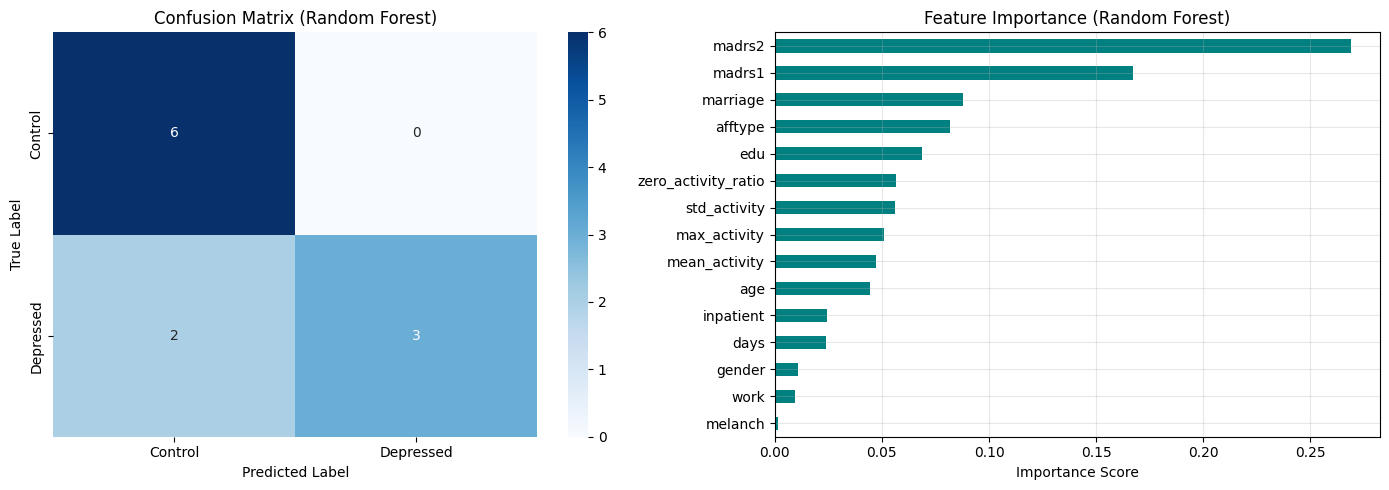

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# 1. التنبؤ باستخدام أفضل موديل تم اختياره (best_model_obj)
y_pred_best = best_model_obj.predict(X_test)

# 2. رسم مصفوفة الارتباك (Confusion Matrix)
cm = confusion_matrix(y_test, y_pred_best)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Control', 'Depressed'],
            yticklabels=['Control', 'Depressed'], ax=ax[0])
ax[0].set_xlabel('Predicted Label')
ax[0].set_ylabel('True Label')
ax[0].set_title(f'Confusion Matrix ({best_model_name})')

# 3. عرض أهم الخصائص المؤثرة (Feature Importance) لأفضل موديل
if hasattr(best_model_obj, 'feature_importances_'):
    feature_importances = pd.Series(best_model_obj.feature_importances_, index=X.columns).sort_values(ascending=True)
    feature_importances.plot(kind='barh', color='teal', ax=ax[1])
    ax[1].set_title(f'Feature Importance ({best_model_name})')
    ax[1].set_xlabel('Importance Score')
    ax[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
import joblib

# فريق الـ Backend هيحمل الموديل كده:
loaded_model = joblib.load('best_depression_model.pkl')

# إدخال بيانات مريض جديد للتنبؤ
# (مثال: mean_activity, std_activity, max_activity, zero_activity_ratio, age, ...الخ)
# prediction = loaded_model.predict(new_patient_data)

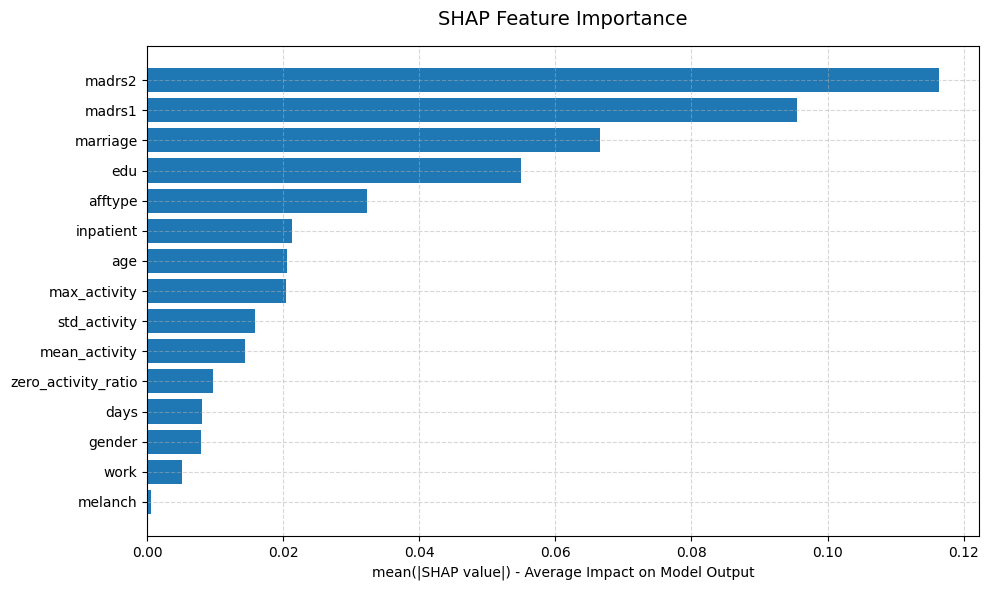

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. تنظيف أي رسم سابق من الذاكرة
plt.close('all')

# 2. معالجة أبعاد shap_values للحصول على مصفوفة أحادية الأبعاد (1D) للفئة المطلوبة (Depressed)
if isinstance(shap_values, list):
    vals = shap_values[1]
else:
    vals = shap_values

# إذا كان الناتج 3D Matrix نأخذ القيم الخاصة بالفئة 1 فقط
if len(vals.shape) == 3:
    vals = vals[:, :, 1]

# حساب متوسط التأثير وتسطيحه ليصبح 1D بشكل صريح
shap_importance = np.abs(vals).mean(axis=0).flatten()

# 3. إنشاء DataFrame وترتيب الخصائص حسب التأثير
importance_df = pd.DataFrame({
    'Feature': X_test.columns,
    'SHAP_Importance': shap_importance
}).sort_values(by='SHAP_Importance', ascending=True)

# 4. رسم المخطط بيانيًا
plt.figure(figsize=(10, 6))
plt.barh(importance_df['Feature'], importance_df['SHAP_Importance'], color='#1f77b4')
plt.xlabel('mean(|SHAP value|) - Average Impact on Model Output')
plt.title('SHAP Feature Importance', fontsize=14, pad=15)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()